# Analítica Empresarial Integrada — Laboratorio D13
## Semana 13 · Gobierno de Datos y Cumplimiento Normativo
**TECSUP 2026-II · Docente: Pilar Rocío Sayán Mejía**

### Auditoría de un modelo
**Sesgo por subgrupos + explicabilidad con SHAP + checklist de gobierno/cumplimiento**

Caso reproducible: **UCI Adult (ID 2)**, que predice si el ingreso anual supera USD 50 000. La fuente corresponde a registros extraídos del censo de Estados Unidos de 1994; no contiene resultados de aprobación crediticia ni de incumplimiento.

> Las variables sensibles se usan para **auditoría**, no para recomendar decisiones discriminatorias. SHAP explica el comportamiento del modelo; **no demuestra causalidad**. Este ejercicio es académico y no valida un modelo para producción.


## Identificación
- **Nombre y apellidos:** Jhadir Abdel Yupanqui Chahua
- **Sección:** C28 6to A-L
- **Enlace de mi Colab:** Pendiente de publicar en mi cuenta de Google Colab.
- **Enlace de mi repositorio GitHub:** [Carpeta semana13](https://github.com/jhadir08/analitica-empresarial-integrada/tree/main/semana13)
- **Uso de IA declarado:** ChatGPT se utilizó como apoyo para comprender la lógica del código y orientar la lectura de los resultados; las respuestas y conclusiones deben ser revisadas y validadas por el estudiante.


In [1]:
# En Colab se instalan solo los paquetes que el laboratorio necesita y que pueden no venir preinstalados.
%pip install -q ucimlrepo shap plotly


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
# Las advertencias de cambios futuros no afectan la ejecución; los errores y resultados sí deben seguir visibles.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
# Herramientas para limpiar datos, estimar el modelo y mostrar resultados.
import numpy as np, pandas as pd
import plotly.express as px
import plotly.io as pio
# Usa un renderizador conectado para guardar HTML ligero y datos Plotly reproducibles.
pio.renderers.default = "notebook_connected"
import matplotlib.pyplot as plt
# Cliente oficial de UCI para descargar el conjunto por su identificador.
from ucimlrepo import fetch_ucirepo
# Componentes del flujo reproducible de entrenamiento y evaluación.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# SHAP descompone la puntuación del modelo en aportes de variables; no infiere causas.
import shap
# Facilita la lectura de tablas con variables categóricas codificadas.
pd.set_option("display.max_columns", 100)


# 1. Fuente, ficha y linaje

In [3]:
# UCI Adult (ID 2): variables de personas y si su ingreso supera 50 000 dólares al año
adult = fetch_ucirepo(id=2)
# X_raw son las variables; y_raw es la variable objetivo
X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

# Trazabilidad: nombre, identificador y dimensiones de la fuente
print("Dataset:", adult.metadata.name)
print("UCI ID: 2")
print("X:", X_raw.shape, "y:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())

Dataset: Adult
UCI ID: 2
X: (48842, 14) y: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


In [4]:
# Limpia el texto: quita espacios y convierte los signos '?' en valores faltantes
def clean_str(s):
    s = s.astype("string").str.strip().replace({"?": pd.NA, "nan": pd.NA})
    return s.astype(object).where(s.notna(), np.nan)

# Se trabaja sobre una copia para conservar los datos originales
X = X_raw.copy()
for c in X.select_dtypes(include=["object","string"]).columns:
    X[c] = clean_str(X[c])

# Variable objetivo: 1 si el ingreso es mayor de 50K, 0 en caso contrario
target = y_raw.iloc[:,0].astype("string").str.strip().str.replace(".", "", regex=False)
y = target.str.contains(">50K", regex=False).astype(int)

# Proporción de cada clase: la clase positiva es minoritaria
print(y.value_counts(normalize=True).rename("proportion"))
# Calidad: cuántos valores faltantes tiene cada variable
print("Nulos por variable:")
display(X.isna().sum().sort_values(ascending=False).head(15))

income
0    0.760718
1    0.239282
Name: proportion, dtype: float64
Nulos por variable:


occupation        2809
workclass         2799
native-country     857
education            0
fnlwgt               0
age                  0
marital-status       0
education-num        0
race                 0
relationship         0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
dtype: int64

### Ficha de gobierno
- **Fuente:** UCI Machine Learning Repository, Adult (ID 2), extracción de la base del censo estadounidense de 1994; 48 842 registros, 14 variables de entrada y una etiqueta de ingreso; contiene faltantes y licencia CC BY 4.0.
- **Finalidad académica:** practicar clasificación y auditoría de desempeño, brechas y explicabilidad; no decidir elegibilidad de crédito.
- **Variable objetivo:** `income` (>50K = 1; ≤50K = 0), indicador de ingreso anual del conjunto Adult.
- **Propietario/responsable propuesto:** custodio del dataset UCI para la fuente; para un eventual caso de negocio, propietario del modelo, responsable de datos y áreas de Riesgo, Cumplimiento y Privacidad.
- **Variables sensibles usadas solo para auditoría:** `race` y `sex`; además, la etiqueta representa un tramo de ingreso y debe tratarse con especial cautela. `sex` y `race` se mantienen fuera del entrenamiento, pero en una aplicación real se requeriría una evaluación de proxies y base legal.
- **Reglas de calidad:** conservar 48 842 filas; normalizar espacios y `?`; convertir faltantes a nulos; imputar variables numéricas con mediana y categóricas con moda, aprendidas solo en entrenamiento; preservar las proporciones de la etiqueta mediante partición estratificada; verificar tamaños de grupos y denominadores de las métricas.
- **Linaje:** UCI Adult → limpieza → separación de atributos de auditoría → partición estratificada 75/25 → imputación, escalado y codificación ajustados en entrenamiento → regresión logística → probabilidades y umbral 0,50 → auditoría por subgrupos y SHAP.


### Pregunta 1
¿Qué información del origen y significado de los datos debería conocer un responsable antes de aprobar el uso del modelo?

**Respuesta:** Debe conocer que UCI Adult reúne 48 842 registros extraídos del censo de EE. UU. de 1994 y predice ingreso anual >USD 50 000; revisar población y criterios de selección, diccionario y unidades (incluido `fnlwgt`), faltantes, licencia, representatividad y antigüedad. También debe identificar la etiqueta y sus límites, los datos personales/sensibles, la finalidad y base legal, el responsable, la calidad, el linaje y si los datos realmente representan el uso previsto. Aquí no hay etiqueta de crédito ni mora.


### Pregunta 2
¿Qué diferencia existe entre tener un archivo de datos y tener datos gobernados?

**Respuesta:** Un archivo almacena valores. Los datos gobernados además tienen propósito y propietario definidos, catálogo y significado documentados, clasificación de sensibilidad, reglas de calidad, linaje, permisos, retención, seguridad, base legal y responsables de corregir problemas. El notebook aporta parte del linaje y de la revisión de calidad, pero no demuestra los controles organizacionales.


# 2. Separación de variables sensibles para auditoría

In [5]:
# Busca una columna aunque cambie la forma de escribir su nombre
def find_col(cols, candidates):
    low={str(c).lower().replace("-","").replace("_","").replace(" ",""):c for c in cols}
    for x in candidates:
        k=x.lower().replace("-","").replace("_","").replace(" ","")
        if k in low: return low[k]
    return None

# Variables sensibles: se usan solo para auditar, no para entrenar
sex_col = find_col(X.columns, ["sex"])
race_col = find_col(X.columns, ["race"])
print("sex:", sex_col, "| race:", race_col)

# Tabla de auditoría con sexo y raza de cada persona
audit = pd.DataFrame(index=X.index)
audit["sex"] = X[sex_col].astype("string").fillna("Missing") if sex_col else "Unavailable"
audit["race"] = X[race_col].astype("string").fillna("Missing") if race_col else "Unavailable"

# Se retiran las variables sensibles de las que entrenan el modelo
drop_sensitive = [c for c in [sex_col, race_col] if c is not None]
X_model = X.drop(columns=drop_sensitive).copy()
# Número de variables que ve el modelo
print("Variables del modelo:", X_model.shape[1])

sex: sex | race: race
Variables del modelo: 12


### Pregunta 3
¿Por qué excluir una variable sensible del entrenamiento no garantiza por sí solo ausencia de sesgo?

**Respuesta:** Otras variables pueden actuar como proxies y reconstruir información asociada: en Adult, `relationship` contiene categorías como “Husband” y “Wife”, y `marital-status` también se relaciona con `sex`. Además, los patrones históricos, la selección de la muestra, la etiqueta y el umbral pueden generar brechas aunque el atributo sensible no esté en las entradas. Hay que medir errores por grupo y revisar proxies.


# 3. Train/test y modelo base

In [6]:
# Partición 75 % / 25 % estratificada por la variable objetivo; la semilla fija repite el resultado
idx_train, idx_test = train_test_split(
    X_model.index, test_size=0.25, random_state=42, stratify=y
)
# Se separan variables y objetivo de entrenamiento y de prueba
X_train, X_test = X_model.loc[idx_train], X_model.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
# La auditoría usa solo las personas de la muestra de prueba
audit_test = audit.loc[idx_test].copy()

# Variables numéricas y categóricas se tratan por separado
num_cols = X_model.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_model.columns if c not in num_cols]

# Numéricas: se completan con la mediana y se estandarizan
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
# Categóricas: se completan con la moda y se codifican en columnas 0/1
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
# Preprocesamiento único para ambos tipos de variables
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
], verbose_feature_names_out=False)

# Regresión logística con pesos balanceados para compensar la clase minoritaria
pipe = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])

# El modelo se ajusta solo con la muestra de entrenamiento
pipe.fit(X_train, y_train)
# Probabilidad estimada de ingreso mayor de 50K
proba = pipe.predict_proba(X_test)[:,1]
# Predicción con umbral de 0,50
pred = (proba >= 0.50).astype(int)

# Métricas globales sobre la muestra de prueba
global_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test,pred),
    "precision": precision_score(y_test,pred,zero_division=0),
    "recall": recall_score(y_test,pred,zero_division=0),
    "f1": f1_score(y_test,pred,zero_division=0)
}])
display(global_metrics.round(4))

,accuracy,precision,recall,f1
0,0.8012,0.5566,0.8323,0.6671


# 4. Auditoría por subgrupos

In [7]:
# Se une la auditoría con el valor real, la predicción y la probabilidad
audit_result = audit_test.copy()
audit_result["y_true"] = y_test
audit_result["y_pred"] = pred
audit_result["proba"] = proba

# Métricas por subgrupo; se omiten grupos de menos de 100 personas
def group_metrics(df, group_col, min_n=100):
    rows=[]
    for g,d in df.groupby(group_col, dropna=False):
        if len(d) < min_n:
            continue
        # Matriz de confusión del grupo: verdaderos y falsos, positivos y negativos
        tn,fp,fn,tp = confusion_matrix(d.y_true,d.y_pred,labels=[0,1]).ravel()
        rows.append({
            "dimension":group_col,
            "group":str(g),
            "n":len(d),
            "positive_rate_pred":d.y_pred.mean(),
            "accuracy":accuracy_score(d.y_true,d.y_pred),
            "recall":recall_score(d.y_true,d.y_pred,zero_division=0),
            "fpr":fp/(fp+tn) if (fp+tn)>0 else np.nan,
            "fnr":fn/(fn+tp) if (fn+tp)>0 else np.nan
        })
    return pd.DataFrame(rows)

# Auditoría por sexo y por raza
gm_sex = group_metrics(audit_result,"sex")
gm_race = group_metrics(audit_result,"race")
# Tabla única con todos los subgrupos
group_table = pd.concat([gm_sex,gm_race],ignore_index=True)
display(group_table.round(4))

,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,sex,Female,4057,0.1541,0.8925,0.7086,0.0844,0.2914
1,sex,Male,8154,0.4592,0.7558,0.8550,0.2872,0.1450
2,race,Amer-Indian-Eskimo,126,0.2698,0.7857,0.8182,0.2174,0.1818
3,race,Asian-Pac-Islander,369,0.3821,0.7751,0.8021,0.2344,0.1979
4,race,Black,1186,0.1804,0.8769,0.7361,0.1036,0.2639
5,race,White,10442,0.3795,0.7932,0.8391,0.2224,0.1609


In [8]:
# Un gráfico de barras por dimensión: recall, tasa de falsos positivos y de falsos negativos
for dim in ["sex","race"]:
    d=group_table[group_table.dimension==dim]
    if len(d):
        fig=px.bar(d,x="group",y=["recall","fpr","fnr"],barmode="group",
                   title=f"Auditoría por subgrupo — {dim}")
        fig.show()

### Pregunta 4
¿Qué métrica global podría ocultar una diferencia importante entre grupos?

**Respuesta:** La accuracy global (0,8012) resume aciertos totales, pero no muestra cómo se distribuyen los errores. Por ejemplo, la accuracy es 0,8925 en mujeres y 0,7558 en hombres; el FPR es 0,0844 frente a 0,2872 y el FNR es 0,2914 frente a 0,1450. También deben revisarse precisión, recall y tasas de error por grupo, junto con sus tamaños.


### Pregunta 5
¿Qué brecha observada merece primero una revisión empresarial? Sustente con magnitud, tamaño de grupo y tipo de error.

**Respuesta:** Revisaría primero la brecha de FPR por `sex`: 0,2872 en hombres (8 154 casos) frente a 0,0844 en mujeres (4 057), diferencia de 20,29 puntos porcentuales. En Adult, son falsos positivos las personas con ingreso real ≤USD 50 000 clasificadas como >USD 50 000. La tasa positiva predicha también difiere 30,51 puntos, pero no es por sí sola una tasa de error. Hay que comprobar definiciones, datos y proxies antes de atribuir causas.


# 5. Brechas cuantificadas

In [9]:
# Brecha = valor más alto menos valor más bajo de una métrica entre subgrupos
def gap_report(tbl, metric):
    x=tbl.dropna(subset=[metric]).copy()
    if len(x)<2: return None
    hi=x.loc[x[metric].idxmax()]
    lo=x.loc[x[metric].idxmin()]
    return {
        "metric":metric,
        "max_group":hi["group"], "max_value":hi[metric],
        "min_group":lo["group"], "min_value":lo[metric],
        "gap":hi[metric]-lo[metric]
    }

# Se calcula la brecha de cuatro métricas en cada dimensión
gaps=[]
for dim in ["sex","race"]:
    t=group_table[group_table.dimension==dim]
    for metric in ["positive_rate_pred","recall","fpr","fnr"]:
        r=gap_report(t,metric)
        if r: r["dimension"]=dim; gaps.append(r)
# Tabla de brechas, de mayor a menor
gap_df=pd.DataFrame(gaps)
display(gap_df.sort_values("gap",ascending=False).round(4))

,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,Male,0.4592,Female,0.1541,0.3051,sex
2,fpr,Male,0.2872,Female,0.0844,0.2029,sex
4,positive_rate_pred,Asian-Pac-Islander,0.3821,Black,0.1804,0.2017,race
1,recall,Male,0.8550,Female,0.7086,0.1464,sex
3,fnr,Female,0.2914,Male,0.1450,0.1464,sex
6,fpr,Asian-Pac-Islander,0.2344,Black,0.1036,0.1308,race
7,fnr,Black,0.2639,White,0.1609,0.1030,race
5,recall,White,0.8391,Black,0.7361,0.1030,race


# 6. Explicabilidad con SHAP

Background dataset has 36631 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=36631 when initializing the masker.


Muestra SHAP: (500, 98)


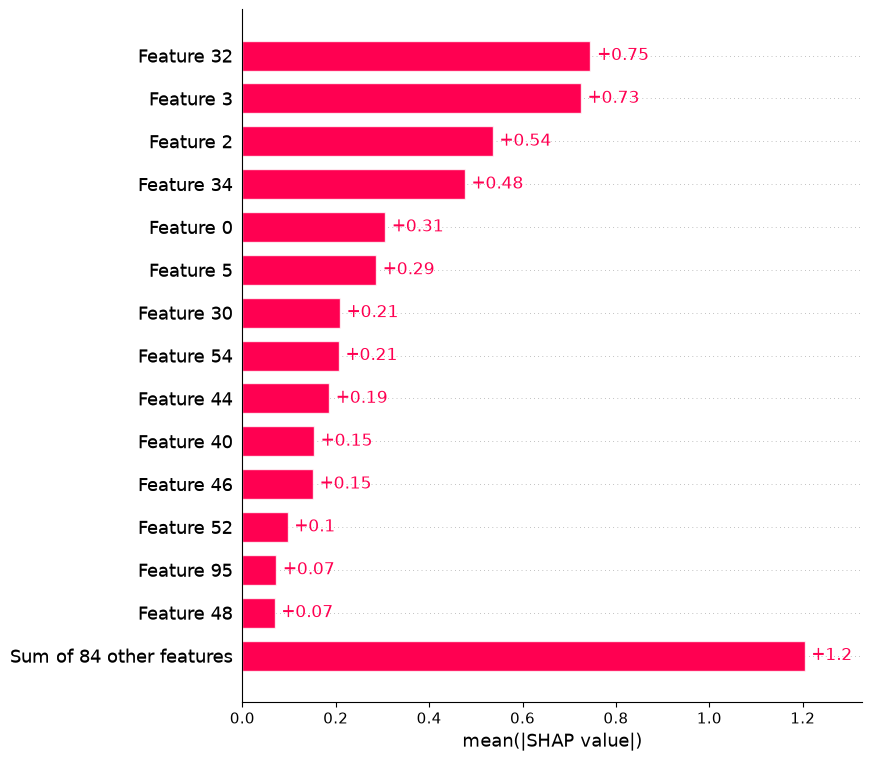

In [10]:
# Se explica la salida lineal del modelo para 500 casos de prueba; el valor explicado está en escala de puntuación/log-odds.
transformer = pipe.named_steps["prep"]
model = pipe.named_steps["model"]
X_train_t = transformer.transform(X_train)
X_test_t = transformer.transform(X_test)
feature_names = transformer.get_feature_names_out()

# Muestra reproducible para que la explicación sea ágil y comparable.
rng = np.random.default_rng(42)
sample_n = min(500, X_test_t.shape[0])
sample_pos = rng.choice(X_test_t.shape[0], size=sample_n, replace=False)
X_shap = X_test_t[sample_pos]

# La regresión logística es lineal en su puntuación; los aportes no son efectos causales.
explainer = shap.LinearExplainer(model, X_train_t)
shap_values = explainer(X_shap)
print("Muestra SHAP:", X_shap.shape)
shap.plots.bar(shap_values, max_display=15)


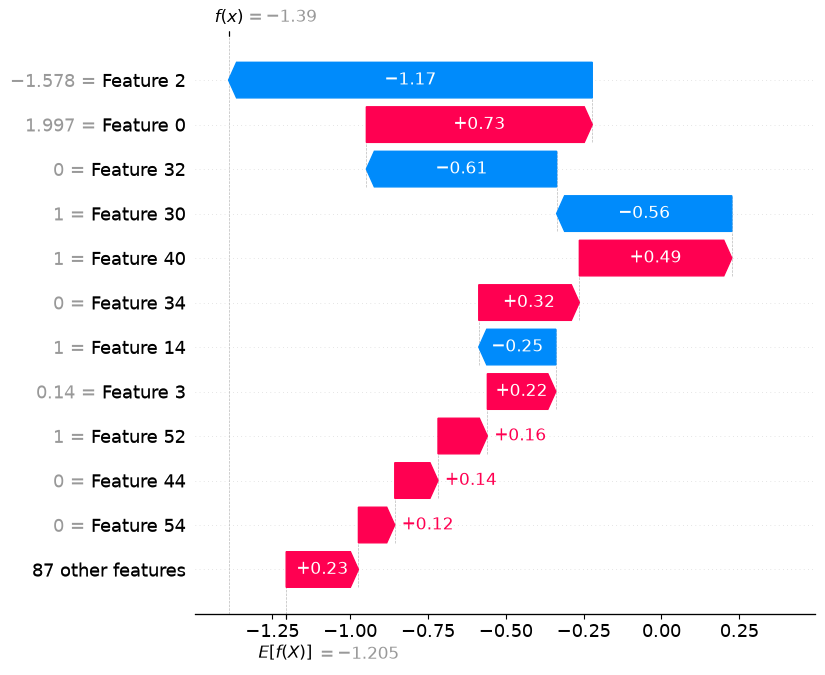

Caso SHAP: base (log-odds)=-1.2054; puntuación=-1.3905; probabilidad estimada=0.1993; clase con umbral 0,50=0
Mayores aportes positivos:


,variable_transformada,valor_codificado,aporte_SHAP_log_odds
0,age,1.9967,0.7256
40,occupation_Exec-managerial,1.0000,0.4897
34,marital-status_Never-married,0.0000,0.3230
3,capital-gain,0.1405,0.2201
52,relationship_Not-in-family,1.0000,0.1585


Mayores aportes negativos:


,variable_transformada,valor_codificado,aporte_SHAP_log_odds
2,education-num,-1.5781,-1.1682
32,marital-status_Married-civ-spouse,0.0000,-0.6111
30,marital-status_Divorced,1.0000,-0.5627
14,education_10th,1.0000,-0.2477
46,occupation_Prof-specialty,0.0000,-0.1020


In [11]:
# El caso 0 corresponde al primer registro de la muestra SHAP fijada arriba.
case = 0
shap.plots.waterfall(shap_values[case], max_display=12)

# La suma de aportes explica la puntuación del modelo; la función logística traduce esa puntuación en probabilidad.
case_margin = float(model.decision_function(X_shap[case:case+1])[0])
case_probability = float(1 / (1 + np.exp(-case_margin)))
base_margin = float(np.asarray(shap_values.base_values[case]).reshape(-1)[0])
print(f"Caso SHAP: base (log-odds)={base_margin:.4f}; puntuación={case_margin:.4f}; probabilidad estimada={case_probability:.4f}; clase con umbral 0,50={int(case_probability >= 0.5)}")
local_contrib = pd.DataFrame({
    "variable_transformada": feature_names,
    "valor_codificado": np.asarray(X_shap[case]).reshape(-1),
    "aporte_SHAP_log_odds": shap_values.values[case]
})
# Los aportes positivos elevan la puntuación relativa al valor base; los negativos la reducen.
print("Mayores aportes positivos:")
display(local_contrib.nlargest(5, "aporte_SHAP_log_odds").round(4))
print("Mayores aportes negativos:")
display(local_contrib.nsmallest(5, "aporte_SHAP_log_odds").round(4))


### Pregunta 6
¿Cuáles variables tienen mayor influencia global en las predicciones?

**Respuesta:** Al agregar los valores absolutos SHAP por variable original, destacan `marital-status` (1,57033), `occupation` (0,81617), `capital-gain` (0,72503) y `education-num` (0,53636). Son aportes medios a la puntuación del modelo en esta muestra; no implican causalidad ni pertinencia para una decisión crediticia.


### Pregunta 7
Elija una predicción y explique qué variables aumentaron o redujeron la probabilidad estimada. No use lenguaje causal.

**Respuesta:** En el caso SHAP 0, la probabilidad estimada es 0,1993 y la clase predicha es 0. Frente al valor base, `age` (+0,7256 log-odds), `occupation_Exec-managerial` (+0,4897) y `capital-gain` (+0,2201) elevan la puntuación; `education-num` (−1,1682), `marital-status_Married-civ-spouse` (−0,6111) y `marital-status_Divorced` (−0,5627) la reducen. Son contribuciones al modelo, no causas del ingreso.


# 7. Checklist académico de gobierno y cumplimiento

In [12]:
# Checklist académico inicial; el ejercicio 5 añade base normativa y estado final sustentado en la evidencia.
checklist = pd.DataFrame([
    ["Finalidad","¿Está documentado para qué se usará el modelo?","Parcial","El propósito académico está descrito; el uso de crédito no es válido para esta etiqueta."],
    ["Minimización","¿Cada variable tiene una justificación de necesidad?","Parcial","Sex y race se excluyen del entrenamiento, pero faltan justificaciones por variable y evaluación completa de proxies."],
    ["Calidad","¿Hay reglas y resultados de calidad de datos?","Parcial","Se muestran nulos y una limpieza reproducible; faltan controles más amplios."],
    ["Linaje","¿Puede seguirse fuente→transformación→modelo→salida?","Cumple","Fuente, limpieza, partición, pipeline, modelo y auditoría están en el notebook."],
    ["Acceso","¿Están definidos roles y permisos sobre datos/modelo?","No evidenciado","El notebook no contiene evidencias de control de acceso."],
    ["Transparencia","¿Se documentan lógica, limitaciones y supervisión?","Parcial","Se presentan métricas, SHAP y límites; falta el proceso de explicación al usuario."],
    ["Auditoría de subgrupos","¿Se revisaron errores y tasas por grupos?","Cumple","Se presentan métricas y brechas para sexo, raza y edad."],
    ["Supervisión humana","¿Existe responsable para revisar decisiones de alto impacto?","No evidenciado","No hay procedimiento organizacional ni facultad de detener o corregir decisiones."],
], columns=["control","pregunta","estado_inicial","evidencia"])
display(checklist)


,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Está documentado para qué se usará el modelo?,Parcial,El propósito académico está descrito; el uso d...
1,Minimización,¿Cada variable tiene una justificación de nece...,Parcial,"Sex y race se excluyen del entrenamiento, pero..."
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,Se muestran nulos y una limpieza reproducible;...
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Cumple,"Fuente, limpieza, partición, pipeline, modelo ..."
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,El notebook no contiene evidencias de control ...
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,"Se presentan métricas, SHAP y límites; falta e..."
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,"Se presentan métricas y brechas para sexo, raz..."
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,No hay procedimiento organizacional ni faculta...


Edite el checklist con uno de estos estados:

- **Cumple**
- **Parcial**
- **No evidenciado**
- **No aplica**

> Este checklist es **académico**. No constituye certificación legal.

### Pregunta 8
¿Qué control no puede demostrarse solo con código y necesita evidencia organizacional adicional?

**Respuesta:** La supervisión humana efectiva: debe existir una persona o equipo responsable, capacitado, con procedimiento y autoridad real para detener, corregir o invalidar una decisión, además de registros de revisión. También los permisos y la aprobación de finalidad/base legal necesitan políticas, asignaciones de rol y evidencias institucionales, no solo código.


# 8. Registro de hallazgos y plan de acción

In [13]:
# Hallazgos verificables y acciones previas a cualquier uso productivo.
hallazgos = pd.DataFrame([
    ["Brecha de FPR por sexo y diferencia en tasa positiva predicha","Alta","Hombres: FPR 0,2872 (n=8 154); mujeres: 0,0844 (n=4 057); brecha 20,28 pp. Tasa positiva: 45,92 % vs 15,41 %. Dataset Adult.","Validar definiciones y calidad; revisar proxies, umbral y consecuencias por grupo con Riesgo y Cumplimiento; repetir pruebas en datos adecuados.","Responsable del modelo + Riesgo + Cumplimiento","Abierto"],
    ["Posibles proxies del atributo sexo","Alta","Ejercicio 1: tablas normalizadas de relationship y marital-status frente a sex.","Cuantificar capacidad de reconstrucción, revisar necesidad de variables y documentar mitigaciones; no asumir que retirar sex elimina la brecha.","Gobierno de datos + Responsable del modelo","Abierto"],
    ["El objetivo del notebook no corresponde a crédito","Crítica","UCI Adult predice ingreso >USD 50 000; no contiene aprobación, mora ni pérdidas crediticias.","No utilizar este modelo en originación; obtener datos representativos del objetivo crediticio y rehacer validación y evaluación de impacto.","Dueño de producto + Riesgo de crédito + Cumplimiento","Abierto"],
    ["Controles organizacionales no evidenciados","Alta","Checklist: acceso y supervisión humana carecen de prueba documental.","Definir política, roles, revisión humana con facultad de anulación, transparencia, gestión de incidentes y conservar evidencias.","Gobierno del modelo + Seguridad + Cumplimiento","Abierto"],
], columns=["hallazgo","severidad","evidencia","accion","responsable","estado"])
display(hallazgos)


,hallazgo,severidad,evidencia,accion,responsable,estado
0,Brecha de FPR por sexo y diferencia en tasa po...,Alta,"Hombres: FPR 0,2872 (n=8 154); mujeres: 0,0844...",Validar definiciones y calidad; revisar proxie...,Responsable del modelo + Riesgo + Cumplimiento,Abierto
1,Posibles proxies del atributo sexo,Alta,Ejercicio 1: tablas normalizadas de relationsh...,"Cuantificar capacidad de reconstrucción, revis...",Gobierno de datos + Responsable del modelo,Abierto
2,El objetivo del notebook no corresponde a crédito,Crítica,UCI Adult predice ingreso >USD 50 000; no cont...,No utilizar este modelo en originación; obtene...,Dueño de producto + Riesgo de crédito + Cumpli...,Abierto
3,Controles organizacionales no evidenciados,Alta,Checklist: acceso y supervisión humana carecen...,"Definir política, roles, revisión humana con f...",Gobierno del modelo + Seguridad + Cumplimiento,Abierto


### Pregunta 9
¿Qué hallazgo impediría desplegar el modelo hasta ser resuelto?

**Respuesta:** La incompatibilidad entre el objetivo del modelo y la decisión prevista: Adult predice ingreso superior a USD 50 000, no incumplimiento ni elegibilidad de crédito. Por tanto, el modelo no demuestra utilidad para originación y no debe desplegarse allí. Además, las brechas observadas y la falta de controles de supervisión humana requieren revisión y mitigación antes de cualquier sistema de alto impacto.


### Pregunta 10
¿Qué evidencia conservaría para demostrar que el modelo fue auditado y revisado antes de su uso?

**Respuesta:** Guardaría versión y huella de los datos, ficha y diccionario, código y dependencias, parámetros, semilla y partición, métricas globales y por grupo con denominadores, matriz de confusión, SHAP global/local, umbral y justificación, hallazgos y acciones, evaluación de impacto y privacidad, aprobaciones de Riesgo/Cumplimiento, responsable y procedimiento de revisión humana, más el plan de monitoreo e incidentes. Debe preservarse cada versión para reproducir la decisión.


# 9. Informe ejecutivo de auditoría
Responda en términos de negocio, con las cifras del notebook (máximo 12 líneas en total).

**A.** En prueba, accuracy = 0,8012, precisión = 0,5566, recall = 0,8323 y F1 = 0,6671. Por sexo, el recall es 0,7086 en mujeres y 0,8550 en hombres; el FPR es 0,0844 y 0,2872, respectivamente. La cifra global no resume esas diferencias.


**B.** La brecha de FPR por sexo es 20,28 pp: hombres 0,2872 (n=8 154) y mujeres 0,0844 (n=4 057). En esta etiqueta, el error es clasificar como >USD 50 000 a alguien cuyo valor real es ≤USD 50 000. La tasa positiva predicha difiere 30,51 pp y requiere contexto adicional.


**C.** Globalmente, la tabla agregada del Ejercicio 4 ordena las variables por promedio de |SHAP|. Para el caso SHAP 0, la cascada y tablas muestran aportes positivos y negativos respecto al valor base; elevan o reducen la puntuación/probabilidad estimada. SHAP describe la salida del modelo, no causas.


**D.** Se revisaron calidad y linaje: se registran faltantes, limpieza, partición y pipeline reproducible; también se auditó desempeño por subgrupos. Faltan evidencia organizacional de permisos de acceso y de una supervisión humana con autoridad para corregir o invalidar decisiones.


**E.** Adult es una muestra histórica de EE. UU. y su objetivo es ingreso, no riesgo crediticio; además se observaron proxies y brechas. **No aprobaría su uso crediticio**. Solo lo mantendría como ejercicio académico; un sistema real requiere datos crediticios pertinentes, validación independiente, evaluación de impacto, mitigación, privacidad y supervisión humana documentadas.


# 10. Reto de aplicación y retroalimentación
Los cinco ejercicios operan sobre `X_model`, `audit`, `audit_result`, `proba`, `shap_values` y `checklist`. Cada respuesta escrita no debe exceder cuatro líneas.

In [14]:
# Objetos de trabajo para la sección de retos.
print("Variables del modelo:", X_model.shape)
print("Auditoría de prueba:", audit_result.shape)
print("Valores SHAP:", shap_values.values.shape)

Variables del modelo: (48842, 12)
Auditoría de prueba: (12211, 5)
Valores SHAP: (500, 98)


## Ejercicio 1 — Detección de variables proxy del sexo
En el Paso 3 se excluyó la variable sex del entrenamiento. Sin embargo, una exclusión solo es efectiva si ninguna otra variable reproduce la información retirada. En este ejercicio deberá comprobar numéricamente si relationship y marital-status, que el modelo sí recibe, permiten reconstruir el sexo de las personas.

**Se solicita:**
- Construir una tabla cruzada entre relationship y el sexo de la tabla de auditoría, normalizada por fila.
- Construir la misma tabla para marital-status.
- Identificar las categorías en que un solo sexo supera el 85 % de los casos.

In [15]:
# La normalización por fila muestra qué proporción de cada categoría corresponde a cada sexo.
proxy_tables = {}
dominant_categories = []
for variable in ["relationship", "marital-status"]:
    table = pd.crosstab(
        X[variable].fillna("Missing"), audit["sex"], normalize="index"
    )
    proxy_tables[variable] = table
    print(f"Distribución de sex dentro de cada categoría de {variable}:")
    display(table.round(3))
    # Se señalan categorías donde un sexo supera el umbral solicitado de 85 %.
    for category, proportions in table.iterrows():
        if proportions.max() > 0.85:
            dominant_categories.append({
                "variable": variable,
                "categoria": category,
                "sexo_predominante": proportions.idxmax(),
                "proporcion": proportions.max()
            })
dominant_proxy_categories = pd.DataFrame(dominant_categories)
print("Categorías con un sexo por encima de 85 %:")
display(dominant_proxy_categories.round(3))


Distribución de sex dentro de cada categoría de relationship:


sex,Female,Male
relationship,,
Husband,0.000,1.000
Not-in-family,0.467,0.533
Other-relative,0.458,0.542
Own-child,0.445,0.555
Unmarried,0.766,0.234
Wife,0.999,0.001


Distribución de sex dentro de cada categoría de marital-status:


sex,Female,Male
marital-status,,
Divorced,0.603,0.397
Married-AF-spouse,0.676,0.324
Married-civ-spouse,0.111,0.889
Married-spouse-absent,0.484,0.516
Never-married,0.448,0.552
Separated,0.608,0.392
Widowed,0.812,0.188


Categorías con un sexo por encima de 85 %:


,variable,categoria,sexo_predominante,proporcion
0,relationship,Husband,Male,1.000
1,relationship,Wife,Female,0.999
2,marital-status,Married-civ-spouse,Male,0.889


**Pregunta 11.** ¿Qué variable funciona como proxy más fuerte del sexo y qué implica para la decisión de excluir sex del modelo?

**Respuesta:** `relationship` es el proxy más fuerte: “Husband” corresponde a hombres en 100 % de la muestra y “Wife” a mujeres en 99,9 %. `marital-status` también aporta una señal (88,9 % hombres en `Married-civ-spouse`). Excluir `sex` evita su uso directo, pero el modelo puede recuperar información relacionada mediante esas categorías; se necesita revisar y justificar proxies y medir sus impactos.


## Ejercicio 2 — Efecto del umbral de decisión sobre las brechas
El modelo base clasifica como positivo a quien supera una probabilidad de 0,50. Ese umbral no es un dato técnico neutral, sino una decisión de negocio que redistribuye los errores entre los grupos. Corresponde medir cómo cambian las brechas por sexo al mover el umbral.

**Se solicita:**
- Recalcular las predicciones con umbrales de 0,30, 0,50 y 0,70.
- Obtener, para cada umbral, el FNR y el FPR de mujeres y de hombres con la función group_metrics.
- Construir las columnas brecha_fnr y brecha_fpr y presentar los resultados en una tabla.

In [16]:
# Un umbral distinto cambia la cantidad y el tipo de errores; medimos FPR y FNR por sexo.
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    audit_at_threshold = audit_test.copy()
    audit_at_threshold["y_true"] = y_test
    audit_at_threshold["y_pred"] = (proba >= threshold).astype(int)
    metrics_at_threshold = group_metrics(audit_at_threshold, "sex")
    metrics_at_threshold["threshold"] = threshold
    threshold_rows.append(metrics_at_threshold)
threshold_metrics = pd.concat(threshold_rows, ignore_index=True)
threshold_metrics = threshold_metrics[["threshold", "group", "n", "positive_rate_pred", "fpr", "fnr"]]
print("Métricas por grupo y umbral:")
display(threshold_metrics.round(4))
# Las brechas son diferencias absolutas entre hombres y mujeres, en puntos de proporción.
threshold_wide = threshold_metrics.pivot(index="threshold", columns="group", values=["fpr", "fnr"])
threshold_gaps = pd.DataFrame({
    "brecha_fpr": (threshold_wide[("fpr", "Male")] - threshold_wide[("fpr", "Female")]).abs(),
    "brecha_fnr": (threshold_wide[("fnr", "Male")] - threshold_wide[("fnr", "Female")]).abs(),
})
print("Brechas absolutas entre sexos:")
display(threshold_gaps.round(4))


Métricas por grupo y umbral:


,threshold,group,n,positive_rate_pred,fpr,fnr
0,0.3,Female,4057,0.2379,0.1615,0.1545
1,0.3,Male,8154,0.5912,0.4355,0.0502
2,0.5,Female,4057,0.1541,0.0844,0.2914
3,0.5,Male,8154,0.4592,0.2872,0.1450
4,0.7,Female,4057,0.0954,0.0366,0.4371
5,0.7,Male,8154,0.2981,0.1321,0.3196


Brechas absolutas entre sexos:


,brecha_fpr,brecha_fnr
threshold,,
0.3,0.2740,0.1043
0.5,0.2029,0.1464
0.7,0.0955,0.1175


**Pregunta 12.** ¿Existe un umbral que elimine a la vez las brechas de FNR y de FPR? ¿Quién debería decidir el umbral final?

**Respuesta:** No. En 0,30 las brechas FPR/FNR son 0,2740/0,1043; en 0,50, 0,2029/0,1464; y en 0,70, 0,0955/0,1175. Ninguno elimina simultáneamente ambas. El umbral debe aprobarlo el dueño de negocio con Riesgo, Cumplimiento, Privacidad y gobierno del modelo, considerando los errores y daños, con decisión y supervisión documentadas.


## Ejercicio 3 — Nueva dimensión de auditoría: grupos de edad
La auditoría de la Actividad 2 se limitó al sexo y a la raza. Un comité de gobierno, sin embargo, suele pedir otras dimensiones de riesgo. La edad es una de ellas: un modelo puede dejar sistemáticamente fuera a los clientes jóvenes, aun cuando la variable age forme parte legítima del modelo.

**Se solicita:**
- Crear la columna grupo_edad en audit_result con los tramos 17-29, 30-49 y 50+.
- Aplicar group_metrics a la nueva dimensión.
- Calcular con gap_report la brecha de FNR y la de tasa positiva predicha.

In [17]:
# pd.cut asigna grupos explícitos; audit_result solo contiene filas de prueba.
audit_result["grupo_edad"] = pd.cut(
    X_test["age"], bins=[16, 29, 49, np.inf], labels=["17-29", "30-49", "50+"]
)
age_table = group_metrics(audit_result, "grupo_edad")
print("Métricas de auditoría por edad:")
display(age_table.round(4))
age_fnr_gap = gap_report(age_table, "fnr")
age_positive_gap = gap_report(age_table, "positive_rate_pred")
print("Brecha de FNR:", age_fnr_gap)
print("Brecha de tasa positiva predicha:", age_positive_gap)


Métricas de auditoría por edad:


,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,grupo_edad,17-29,3663,0.0975,0.9233,0.7135,0.0660,0.2865
1,grupo_edad,30-49,5868,0.4385,0.7682,0.8266,0.2588,0.1734
2,grupo_edad,50+,2680,0.5369,0.7067,0.8681,0.3731,0.1319


Brecha de FNR: {'metric': 'fnr', 'max_group': '17-29', 'max_value': np.float64(0.28651685393258425), 'min_group': '50+', 'min_value': np.float64(0.1319052987598647), 'gap': np.float64(0.15461155517271954)}
Brecha de tasa positiva predicha: {'metric': 'positive_rate_pred', 'max_group': '50+', 'max_value': np.float64(0.5369402985074627), 'min_group': '17-29', 'min_value': np.float64(0.09746109746109746), 'gap': np.float64(0.4394792010463653)}


**Pregunta 13.** ¿Qué grupo de edad resulta más afectado por los falsos negativos y qué tamaño tiene?

**Respuesta:** El grupo de 17–29 años tiene el FNR más alto: 0,2865 (28,65 %) y 3 663 personas; el de 50+ registra 0,1319. Aquí un falso negativo es un ingreso real >USD 50 000 clasificado como ≤USD 50 000. La diferencia exige investigar los datos y el modelo, sin atribuir causalidad a la edad.


## Ejercicio 4 — Importancia SHAP agregada por variable original
El gráfico SHAP del Paso 7 muestra columnas transformadas: cada categoría de una variable aparece por separado. Esa fragmentación puede subestimar el peso real de una variable categórica con muchas categorías. Corresponde agregar la importancia de cada columna one-hot a su variable original.

**Se solicita:**
- Calcular el promedio del valor SHAP absoluto de cada columna transformada.
- Asignar cada columna a su variable original.
- Sumar la importancia por variable original y ordenarla de mayor a menor.

In [18]:
# La media del aporte absoluto mide importancia global en la escala explicada por SHAP.
mean_abs_shap = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=feature_names, name="mean_abs_SHAP"
)
original_feature = {}
for transformed in feature_names:
    if transformed in num_cols:
        original_feature[transformed] = transformed
        continue
    # El prefijo más largo evita confundir nombres originales que comparten texto.
    matches = [col for col in cat_cols if transformed.startswith(f"{col}_")]
    if not matches:
        raise ValueError(f"No se pudo asignar la variable original a {transformed}")
    original_feature[transformed] = max(matches, key=len)
shap_importance = (
    mean_abs_shap.rename_axis("variable_transformada").reset_index()
    .assign(variable_original=lambda d: d["variable_transformada"].map(original_feature))
    .groupby("variable_original", as_index=False)["mean_abs_SHAP"].sum()
    .sort_values("mean_abs_SHAP", ascending=False)
)
print("Importancia SHAP agregada por variable original:")
display(shap_importance.round(5))


Importancia SHAP agregada por variable original:


,variable_original,mean_abs_SHAP
7,marital-status,1.57033
9,occupation,0.81617
1,capital-gain,0.72503
4,education-num,0.53636
10,relationship,0.46473
0,age,0.30597
6,hours-per-week,0.28653
3,education,0.23440
11,workclass,0.21410
8,native-country,0.18799


**Pregunta 14.** ¿Qué variable original concentra mayor importancia y qué relación tiene con el hallazgo del Ejercicio 1?

**Respuesta:** `marital-status` concentra la mayor importancia agregada (media de |SHAP| = 1,57033). Se relaciona con el Ejercicio 1 porque `Married-civ-spouse` está compuesto por hombres en 88,9 % de la muestra; además, `relationship` contiene “Husband”/“Wife”. La importancia indica uso predictivo y posible proxy, no causalidad ni discriminación demostrada por sí sola.


## Ejercicio 5 — Checklist con base normativa y estado final
El checklist del Paso 8 enumera controles, pero no indica qué norma o marco sustenta cada uno. Un comité necesita esa trazabilidad para priorizar. En este ejercicio deberá vincular cada control con su base normativa y asignar un estado final sustentado en la evidencia obtenida.

**Se solicita:**
- Agregar la columna base_normativa (Ley 29733 y DS 016-2024-JUS, Ley 31814 y DS 115-2025-PCM o DAMA-DMBOK).
- Agregar la columna estado_final con los estados Cumple, Parcial, No evidenciado o No aplica.
- Contar los controles por estado final.

In [19]:
# Se vincula cada control a marcos de referencia y se actualiza su estado según evidencia del laboratorio.
normative_base = {
    "Finalidad": "Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK",
    "Minimización": "Ley 29733 + DS 016-2024-JUS; DAMA-DMBOK",
    "Calidad": "Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK",
    "Linaje": "Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK",
    "Acceso": "Ley 29733 + DS 016-2024-JUS; DAMA-DMBOK",
    "Transparencia": "Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK",
    "Auditoría de subgrupos": "Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK",
    "Supervisión humana": "Ley 31814 + DS 115-2025-PCM",
}
final_status = {
    "Finalidad": "Parcial",
    "Minimización": "Parcial",
    "Calidad": "Parcial",
    "Linaje": "Cumple",
    "Acceso": "No evidenciado",
    "Transparencia": "Parcial",
    "Auditoría de subgrupos": "Cumple",
    "Supervisión humana": "No evidenciado",
}
checklist["base_normativa"] = checklist["control"].map(normative_base)
checklist["estado_final"] = checklist["control"].map(final_status)
print("Checklist con base de referencia y estado final:")
display(checklist)
print("Cantidad de controles por estado final:")
display(checklist["estado_final"].value_counts().rename_axis("estado_final").to_frame("cantidad"))


Checklist con base de referencia y estado final:


,control,pregunta,estado_inicial,evidencia,base_normativa,estado_final
0,Finalidad,¿Está documentado para qué se usará el modelo?,Parcial,El propósito académico está descrito; el uso d...,Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK,Parcial
1,Minimización,¿Cada variable tiene una justificación de nece...,Parcial,"Sex y race se excluyen del entrenamiento, pero...",Ley 29733 + DS 016-2024-JUS; DAMA-DMBOK,Parcial
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,Se muestran nulos y una limpieza reproducible;...,Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK,Parcial
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Cumple,"Fuente, limpieza, partición, pipeline, modelo ...",Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK,Cumple
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,El notebook no contiene evidencias de control ...,Ley 29733 + DS 016-2024-JUS; DAMA-DMBOK,No evidenciado
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,"Se presentan métricas, SHAP y límites; falta e...",Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK,Parcial
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,"Se presentan métricas y brechas para sexo, raz...",Ley 31814 + DS 115-2025-PCM; DAMA-DMBOK,Cumple
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,No hay procedimiento organizacional ni faculta...,Ley 31814 + DS 115-2025-PCM,No evidenciado


Cantidad de controles por estado final:


,cantidad
estado_final,
Parcial,4
Cumple,2
No evidenciado,2


**Pregunta 15.** ¿Cuántos controles quedan como No evidenciado y qué acción concreta propone para cada uno?

**Respuesta:** La tabla de conteo muestra **2 controles No evidenciados**. Para acceso: definir perfiles y mínimo privilegio, registrar altas/bajas y revisar accesos periódicamente. Para supervisión humana: designar revisores capacitados, establecer criterios de escalamiento y documentar su autoridad para detener, corregir o invalidar la recomendación, con trazas de cada revisión.


# 11. Retroalimentación final — DAMA-DMBOK y marco normativo

**Pregunta 16.** A partir de lo realizado, identifique qué áreas de conocimiento de DAMA-DMBOK se evidencian directamente en este laboratorio. Justifique en un máximo de tres líneas.

**Respuesta:** Se evidencian Gobierno de Datos, porque se definen finalidad, responsables y controles; Calidad de Datos, al detectar faltantes y normalizar valores; y Gestión de Metadatos/linaje, al identificar fuente, variables y transformaciones. Seguridad y privacidad se plantean en el checklist, pero el notebook no demuestra su implantación organizacional.


**Pregunta 17.** Ley 29733 y DS 016-2024-JUS. ¿Qué datos del caso tendrían la condición de datos sensibles y qué obligación deriva de ello?

**Respuesta:** La variable `race` se refiere al origen racial/étnico y la etiqueta `income` representa ingresos económicos; ambos están comprendidos como datos sensibles por la Ley 29733. En un tratamiento real se requeriría una finalidad y base legal válidas, información al titular y protección reforzada; si se emplea consentimiento, el DS 016-2024-JUS exige que el de datos sensibles sea otorgado por escrito. Deben limitarse acceso y conservación. `sex` y `age` son datos personales y atributos relevantes para auditoría, pero no se deben etiquetar automáticamente como datos sensibles sin evaluar la definición y contexto aplicables.


**Pregunta 18.** Ley 31814 y DS 115-2025-PCM. ¿En qué nivel de riesgo ubicaría el uso del modelo y qué control sería indispensable antes de desplegarlo?

**Respuesta:** Un sistema de IA que determina evaluación crediticia es de **riesgo alto** (DS 115-2025-PCM, art. 24.1(g), excepto detección de fraude financiero). Antes de implementarlo deben documentarse la evaluación de impacto de riesgo alto y las mitigaciones de sesgo; en finanzas también se exige supervisión humana capacitada con capacidad de detener, corregir o invalidar decisiones. Este notebook es un ejercicio y no cumple ni reemplaza dicha evaluación.


# 12. Conclusiones
1. La regresión logística logra accuracy 0,8012 en Adult, pero la evaluación por subgrupos muestra brechas en tasas de error que requieren investigación.
2. Excluir `sex` y `race` del entrenamiento no elimina proxies; SHAP explica contribuciones al resultado del modelo, no causas.
3. No se aprueba el uso para crédito: el objetivo Adult es ingreso, y un sistema crediticio requeriría datos pertinentes, evaluación de impacto, controles de privacidad, gobernanza y supervisión humana documentada.


# 13. Checklist de entrega
- [x] UCI Adult ID 2 visible y fuente descrita.
- [x] Ficha de datos y linaje.
- [x] Variables sensibles separadas para auditoría.
- [x] Train/test reproducible.
- [x] Métricas globales y por sexo y raza.
- [x] Brechas cuantificadas.
- [x] SHAP global y local, con lectura no causal.
- [x] Checklist de gobierno/cumplimiento con bases de referencia.
- [x] Registro de hallazgos y plan de acción.
- [x] Informe ejecutivo.
- [x] Cinco retos resueltos.
- [x] Limitación explícita: Adult no es un dataset de crédito.
- [x] No se presenta el notebook como certificación legal.
- [ ] Enlace de Colab pendiente de publicar por el estudiante.
- [x] Enlace de GitHub previsto para la carpeta semana13/.


# Referencias
- Becker, B. & Kohavi, R. (1996). [Adult, UCI Machine Learning Repository, ID 2](https://archive.ics.uci.edu/dataset/2/adult). DOI: 10.24432/C5XW20.
- DAMA International. *DAMA-DMBOK: Data Management Body of Knowledge*, 2.ª ed. revisada.
- Molnar, C. [Interpretable Machine Learning — SHAP](https://christophm.github.io/interpretable-ml-book/shap.html).
- Perú. [Ley N.º 29733, Ley de Protección de Datos Personales](https://www.congreso.gob.pe/Docs/DGP/DIDP/files/ley_29733.pdf).
- Perú. [Decreto Supremo N.º 016-2024-JUS, Reglamento de la Ley N.º 29733](https://www.gob.pe/institucion/anpd/normas-legales/6554453-16-2024-jus).
- Perú. [Ley N.º 31814, Ley que promueve el uso de la inteligencia artificial](https://busquedas.elperuano.pe/dispositivo/NL/2192926-1).
- Perú. [Decreto Supremo N.º 115-2025-PCM, Reglamento de la Ley N.º 31814](https://busquedas.elperuano.pe/dispositivo/NL/2436426-1).
- Sílabo de Analítica Empresarial Integrada, TECSUP 2026-II.
